<a href="https://colab.research.google.com/github/mokshpatel098-ux/HEALTH-CARE/blob/main/HEALTHCARE_STROKE_PREDICTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TASK 2
P4

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

pd.set_option('display.max_columns', None)
#write a note

from google.colab import files
upload = files.upload()

# Load the uploaded file into a DataFrame
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print("Dataset shapes:", df.shape)
df.head()

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv
Dataset shapes: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Loaded the Kaggle dataset: 5,110 rows, 12 columns.

In [ ]:
# Load the uploaded CSV file into a pandas DataFrame
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Step 2 initial audit


Data types and non-null counts. Only BMI has missing values.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


BMI has 201 missing values (3.93%).

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())
print()

bmi_missing_count = df['bmi'].isnull().sum()
bmi_missing_percentage = df['bmi'].isnull().mean() * 100
print(f"BMI missing: {bmi_missing_count} rows ({bmi_missing_percentage:.2f}% of dataset)")
for col in ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]:
    print(col, "->", df[col].unique().tolist())
display(df.describe().round(2))


Missing values per column:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

BMI missing: 201 rows (3.93% of dataset)
gender -> ['Male', 'Female', 'Other']
ever_married -> ['Yes', 'No']
work_type -> ['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Residence_type -> ['Urban', 'Rural']
smoking_status -> ['formerly smoked', 'never smoked', 'smokes', 'Unknown']


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.00,5110.0,5110.00,5110.00,4909.00,5110.00
mean,36517.83,43.23,0.1,0.05,106.15,28.89,0.05
std,21161.72,22.61,0.3,0.23,45.28,7.85,0.22
min,67.00,0.08,0.0,0.00,55.12,10.30,0.00
25%,17741.25,25.00,0.0,0.00,77.24,23.50,0.00
50%,36932.00,45.00,0.0,0.00,91.88,28.10,0.00
75%,54682.00,61.00,0.0,0.00,114.09,33.10,0.00
max,72940.00,82.00,1.0,1.00,271.74,97.60,1.00


In [ ]:
print("Target class balance (stroke):")
print(df['stroke'].value_counts())
print(f"\nstroke cases represent {df['stroke'].mean()*100:.2f}% of the dataset - a significant class imbalance.")

Target class balance (stroke):
stroke
0    4861
1     249
Name: count, dtype: int64

stroke cases represent 4.87% of the dataset - a significant class imbalance.


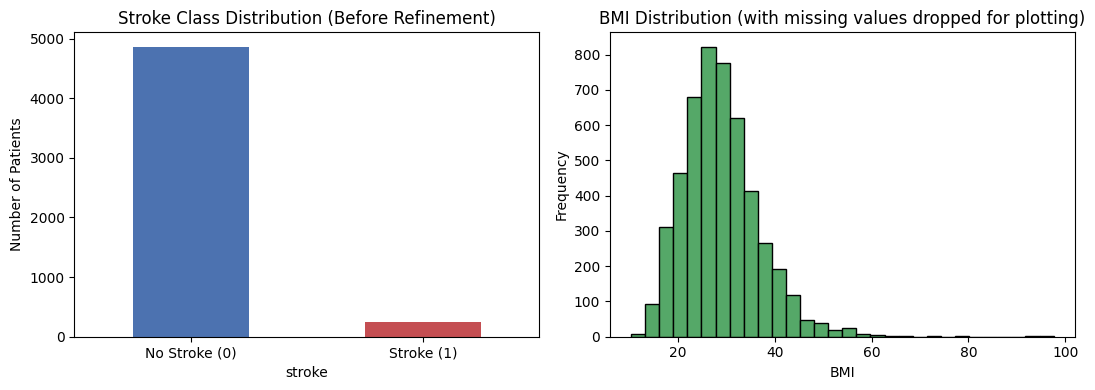

In [ ]:
import os
import matplotlib.pyplot as plt

# make sure the reports folder exists before saving
os.makedirs('../reports', exist_ok=True)

# set up two charts side by side
fig, axs = plt.subplots(1, 2, figsize=(11, 4))

# chart 1: how many patients had a stroke vs no stroke
df['stroke'].value_counts().plot(kind='bar', ax=axs[0], color=['#4C72B0', '#C44E52'])
axs[0].set_title('Stroke Class Distribution (Before Refinement)')
axs[0].set_xticklabels(['No Stroke (0)', 'Stroke (1)'], rotation=0)
axs[0].set_ylabel('Number of Patients')

# chart 2: BMI distribution (NaN values get skipped automatically)
df['bmi'].plot(kind='hist', bins=30, ax=axs[1], color='#55A868', edgecolor='black')
axs[1].set_title('BMI Distribution (with missing values dropped for plotting)')
axs[1].set_xlabel('BMI')

# clean up spacing, then save and show
plt.tight_layout()
plt.savefig('../reports/fig1_class_and_bmi_before.png', dpi=120)
plt.show()

Step 3 Data cleaning add (coments

add comments here

In [ ]:
# check and add comments
df['bmi_missing'] = df['bmi'].isnull()
print(df.groupby('bmi_missing')['age'].mean())

bmi_missing
False    42.865374
True     52.049154
Name: age, dtype: float64


write a note and explain here

In [ ]:
# split ages into groups, only used to help fill missing BMI
age_band = pd.cut(df['age'], bins=[0, 18, 35, 50, 65, 100])

# keep a copy of the original BMI
bmi_before = df['bmi'].copy()

# median BMI for each patient's age group
group_median = df.groupby(age_band, observed=True)['bmi'].transform('median')

# fill the missing BMI values with their group's median
df['bmi'] = df['bmi'].fillna(group_median)

# remove the helper column if it exists
df = df.drop(columns=['bmi_missing'], errors='ignore')

print("Missing BMI values remaining:", df['bmi'].isnull().sum())

Missing BMI values remaining: 0


In [ ]:
# Remove the 'id' column - it is a distinct identifier with no predictive value
df.drop(columns=['id'], inplace=True)

# Only 1 row has the 'Other' gender category - too few to model reliably, so it is dropped
print("Gender value counts before cleaning:")
print(df['gender'].value_counts())
df = df.loc[df['gender'] != 'Other'].reset_index(drop=True)
print("\nRows after dropping the single 'Other' gender row:", df.shape[0])

Gender value counts before cleaning:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Rows after dropping the single 'Other' gender row: 5109


Step 4:Encording categorical variable

In [ ]:
cat_columns = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
print("Categorical columns and their unique values:")
for column in cat_columns:
    print(f"  {column}: {df[column].unique().tolist()}")

Categorical columns and their unique values:
  gender: ['Male', 'Female']
  ever_married: ['Yes', 'No']
  work_type: ['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
  Residence_type: ['Urban', 'Rural']
  smoking_status: ['formerly smoked', 'never smoked', 'smokes', 'Unknown']


In [ ]:
# Convert text columns to numbers (the model only understands numbers)

# Columns with only two options: 0 and 1
df['gender'] = df['gender'].map({'Male': 0, 'Female': 1})
df['ever_married'] = df['ever_married'].map({'No': 0, 'Yes': 1})
df['Residence_type'] = df['Residence_type'].map({'Rural': 0, 'Urban': 1})

# Columns with more than two options: make a new column for each one
df = pd.get_dummies(df, columns=['work_type', 'smoking_status'], drop_first=True, dtype=int)

# Check that it worked
print(df.head())
print(df.shape)

   gender   age  hypertension  heart_disease  ever_married  Residence_type  \
0       0  67.0             0              1             1               1   
1       1  61.0             0              0             1               0   
2       0  80.0             0              1             1               0   
3       1  49.0             0              0             1               1   
4       1  79.0             1              0             1               0   

   avg_glucose_level   bmi  stroke  work_type_Never_worked  work_type_Private  \
0             228.69  36.6       1                       0                  1   
1             202.21  30.5       1                       0                  0   
2             105.92  32.5       1                       0                  1   
3             171.23  34.4       1                       0                  1   
4             174.12  24.0       1                       0                  0   

   work_type_Self-employed  work_type_childr

The test splitting


In [ ]:
# Split the data into inputs (X) and the target we want to predict (y)
X = df.drop(columns=['stroke'])
y = df['stroke']

# 80% of the data for training, 20% for testing
# stratify keeps the stroke percentage the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Check the sizes and the stroke percentage in each set
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Stroke % in training set:", round(y_train.mean() * 100, 2))
print("Stroke % in testing set:", round(y_test.mean() * 100, 2))

Training set: (4087, 15)
Testing set: (1022, 15)
Stroke % in training set: 4.87
Stroke % in testing set: 4.89


In [ ]:
# Put age, glucose and bmi on a similar scale
num_cols = ['age', 'avg_glucose_level', 'bmi']
scaler = StandardScaler()

# Learn the scale from the training data, then apply it to both sets
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# Check the result
print(X_train[num_cols].describe().round(2))

           age  avg_glucose_level      bmi
count  4087.00            4087.00  4087.00
mean     -0.00               0.00    -0.00
std       1.00               1.00     1.00
min      -1.91              -1.13    -2.39
25%      -0.81              -0.64    -0.68
50%       0.08              -0.31    -0.07
75%       0.78               0.18     0.51
max       1.71               3.71     8.86


Only about 5% of patients had a stroke, so the data is very uneven. I used SMOTE on the training data to add more stroke examples. The test data was left alone.

In [ ]:
# Check how uneven the training data is
print("Before balancing:", y_train.value_counts().to_dict())

# SMOTE makes new examples of the rare stroke class
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

# Check the result
print("After balancing:", y_train_bal.value_counts().to_dict())

Before balancing: {0: 3888, 1: 199}
After balancing: {0: 3888, 1: 3888}


After cleaning, no BMI values are missing and the training data is balanced. Compared with the start, 201 missing BMI values were filled and the stroke class went from about 5% to 50% of the training data.

In [ ]:
# summary of the data after cleaning
print("Missing BMI values now:", df['bmi'].isnull().sum())
print("Rows in the cleaned data:", df.shape[0])
print("Training set before SMOTE:", y_train.value_counts().to_dict())
print("Training set after SMOTE:", y_train_bal.value_counts().to_dict())

Missing BMI values now: 0
Rows in the cleaned data: 5109
Training set before SMOTE: {0: 3888, 1: 199}
Training set after SMOTE: {0: 3888, 1: 3888}


TASK 3
(P5): train the first Logistic Regression model, with its charts.

Accuracy: 0.952
Precision: 1.0
Recall: 0.02
F1 score: 0.039

              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



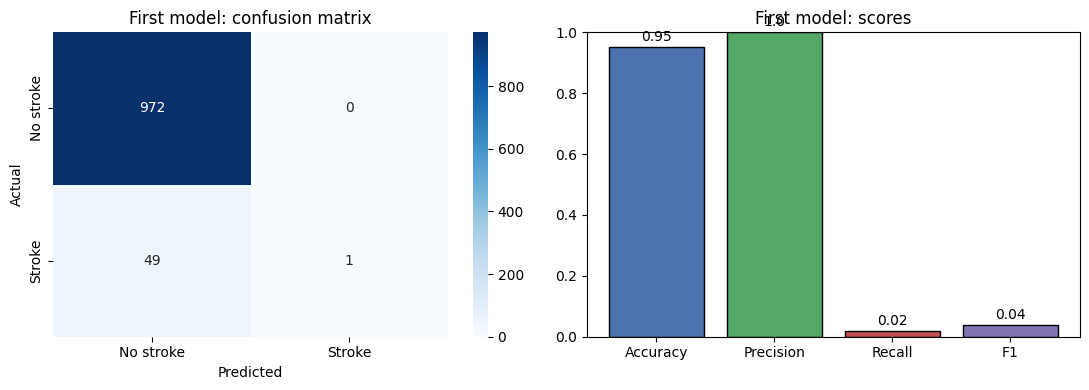

In [ ]:
import os
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

os.makedirs('reports', exist_ok=True)

# first model, trained on the original data
model1 = LogisticRegression(max_iter=1000, random_state=42)
model1.fit(X_train, y_train)

# predict on the test set
pred1 = model1.predict(X_test)

# scores
acc = accuracy_score(y_test, pred1)
prec = precision_score(y_test, pred1, zero_division=0)
rec = recall_score(y_test, pred1, zero_division=0)
f1 = f1_score(y_test, pred1, zero_division=0)

print("Accuracy:", round(acc, 3))
print("Precision:", round(prec, 3))
print("Recall:", round(rec, 3))
print("F1 score:", round(f1, 3))
print()
print(classification_report(y_test, pred1, zero_division=0))

# chart 1: confusion matrix, chart 2: bar chart of the scores
fig, axs = plt.subplots(1, 2, figsize=(11, 4))

cm = confusion_matrix(y_test, pred1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axs[0],
            xticklabels=['No stroke', 'Stroke'],
            yticklabels=['No stroke', 'Stroke'])
axs[0].set_title('First model: confusion matrix')
axs[0].set_xlabel('Predicted')
axs[0].set_ylabel('Actual')

scores = [acc, prec, rec, f1]
names = ['Accuracy', 'Precision', 'Recall', 'F1']
axs[1].bar(names, scores, color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'], edgecolor='black')
axs[1].set_ylim(0, 1)
axs[1].set_title('First model: scores')
for i, s in enumerate(scores):
    axs[1].text(i, s + 0.02, round(s, 2), ha='center')

plt.tight_layout()
plt.savefig('reports/fig2_first_model.png', dpi=120)
plt.show()

In [ ]:
# second model, trained on the balanced data
model2 = LogisticRegression(max_iter=1000, random_state=42)
model2.fit(X_train_bal, y_train_bal)

# predict on the same test set
pred2 = model2.predict(X_test)

acc2 = accuracy_score(y_test, pred2)
prec2 = precision_score(y_test, pred2, zero_division=0)
rec2 = recall_score(y_test, pred2, zero_division=0)
f12 = f1_score(y_test, pred2, zero_division=0)

print("Accuracy:", round(acc2, 3))
print("Precision:", round(prec2, 3))
print("Recall:", round(rec2, 3))
print("F1 score:", round(f12, 3))

Accuracy: 0.739
Precision: 0.132
Recall: 0.78
F1 score: 0.226


In [ ]:
print(classification_report(y_test, pred2, zero_division=0))

              precision    recall  f1-score   support

           0       0.98      0.74      0.84       972
           1       0.13      0.78      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.76      0.53      1022
weighted avg       0.94      0.74      0.81      1022



Confusion Matrics

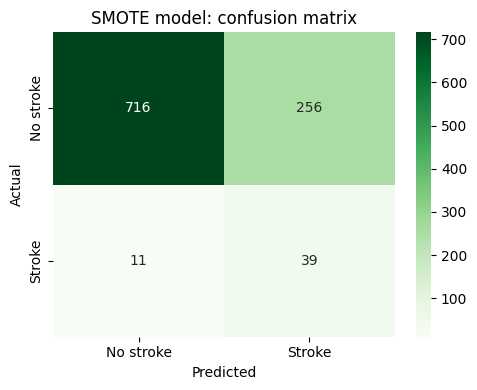

In [ ]:
# confusion matrix of the SMOTE model
cm2 = confusion_matrix(y_test, pred2)

plt.figure(figsize=(5, 4))
sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No stroke', 'Stroke'],
            yticklabels=['No stroke', 'Stroke'])
plt.title('SMOTE model: confusion matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('reports/fig3_smote_matrix.png', dpi=120)
plt.show()

The SMOTE model caught 39 of the 50 real stroke cases and missed 11. It also flagged 256 healthy patients as possible strokes. This is the trade-off for a much higher recall.

In [ ]:
# scores from the two models
labels = ['Accuracy', 'Precision', 'Recall', 'F1']
first_scores = [acc, prec, rec, f1]
smote_scores = [acc2, prec2, rec2, f12]

pos = np.arange(len(labels))

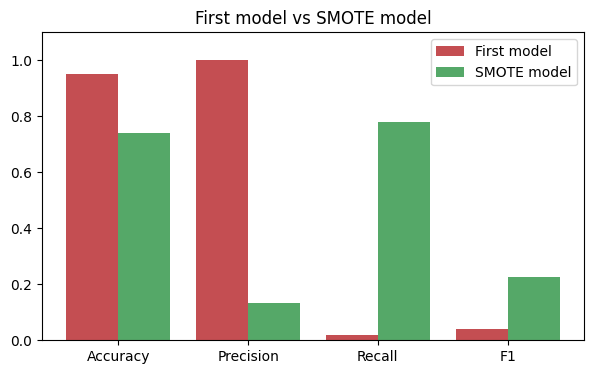

In [ ]:
plt.figure(figsize=(7, 4))

# red bars = first model, green bars = SMOTE model
plt.bar(pos - 0.2, first_scores, width=0.4, label='First model', color='#C44E52')
plt.bar(pos + 0.2, smote_scores, width=0.4, label='SMOTE model', color='#55A868')

plt.xticks(pos, labels)
plt.ylim(0, 1.1)
plt.title('First model vs SMOTE model')
plt.legend()

plt.savefig('reports/fig3_before_after.png', dpi=120)
plt.show()

Recall went from 0.02 to 0.78 after SMOTE, while accuracy and precision dropped. Catching strokes matters more here than overall accuracy.

I tried different values of C, the regularisation strength, and kept the one with the best recall, because catching strokes matters most. The best model was tested on the same test set.

In [ ]:
from sklearn.model_selection import GridSearchCV

# values of C to try
c_values = {'C': [0.01, 0.1, 1, 10, 100]}

search = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42),
                      c_values, scoring='recall', cv=5)
search.fit(X_train_bal, y_train_bal)

print("Best C:", search.best_params_['C'])

Best C: 0.01


In [ ]:
# test the best model on the same test set
model3 = search.best_estimator_
pred3 = model3.predict(X_test)

acc3 = accuracy_score(y_test, pred3)
prec3 = precision_score(y_test, pred3, zero_division=0)
rec3 = recall_score(y_test, pred3, zero_division=0)
f13 = f1_score(y_test, pred3, zero_division=0)

print("Accuracy:", round(acc3, 3))
print("Precision:", round(prec3, 3))
print("Recall:", round(rec3, 3))
print("F1 score:", round(f13, 3))

Accuracy: 0.737
Precision: 0.136
Recall: 0.82
F1 score: 0.234


Cross-validation chose C = 0.01 as the best value. The tuned model raised stroke recall from 0.78 to 0.82 with almost no change in accuracy (0.737). This meets my targets of 70% for both accuracy and recall.

Comparison of the three models on the same test set.

In [ ]:
from sklearn.metrics import roc_auc_score

# the three models we trained
model_list = [("First model", model1),
              ("SMOTE model", model2),
              ("SMOTE + tuned C", model3)]

In [ ]:
table = []

for name, m in model_list:
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]

    table.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 3),
        "Precision": round(precision_score(y_test, pred, zero_division=0), 3),
        "Recall": round(recall_score(y_test, pred, zero_division=0), 3),
        "F1": round(f1_score(y_test, pred, zero_division=0), 3),
        "ROC-AUC": round(roc_auc_score(y_test, prob), 3),
    })

In [ ]:
comparison = pd.DataFrame(table)
print(comparison.to_string(index=False))

          Model  Accuracy  Precision  Recall    F1  ROC-AUC
    First model     0.952      1.000    0.02 0.039    0.839
    SMOTE model     0.739      0.132    0.78 0.226    0.820
SMOTE + tuned C     0.737      0.136    0.82 0.234    0.837


The first model had the highest accuracy (0.952) but found almost no strokes (recall 0.02). SMOTE and tuning raised recall to 0.82 at a small cost in accuracy (0.737). The tuned model is my final model because it catches the most strokes. ROC-AUC stayed similar across models (about 0.84), so the improvement came mainly from balancing the data.

D2: evaluate the effectiveness of the AI solution. First the ROC curve and confusion matrix comparison.

Confusion matrix and ROC curve of the final model compared with the first model.

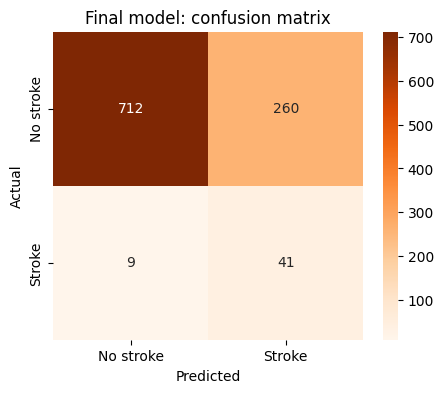

In [ ]:
pred3 = model3.predict(X_test)
cm3 = confusion_matrix(y_test, pred3)

plt.figure(figsize=(5, 4))
sns.heatmap(cm3, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['No stroke', 'Stroke'],
            yticklabels=['No stroke', 'Stroke'])
plt.title('Final model: confusion matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('reports/fig4_final_matrix.png', dpi=120)
plt.show()

The final model caught 41 of the 50 real stroke cases and missed 9. It also flagged 260 healthy patients as possible strokes. Compared with the first model, which caught only 1 stroke, this is a big improvement, and the cost is more false alarms.

The ROC curve

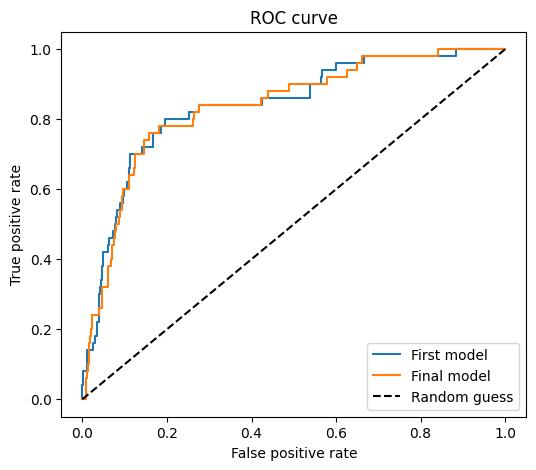

In [ ]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(6, 5))

for name, m in [("First model", model1), ("Final model", model3)]:
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=name)

# the diagonal line is random guessing
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')

plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.legend()
plt.savefig('reports/fig5_roc.png', dpi=120)
plt.show()

Both curves are well above the random-guess line, so the model separates stroke and non-stroke patients reasonably well. The two curves are almost identical, which means the improvement came from balancing the data and moving the cut-off, not from a better ranking of patients.

The coefficients show which features push the prediction towards stroke. A bigger positive value means a stronger link to stroke.

In [ ]:
# coefficient of each feature in the final model
coefs = pd.Series(model3.coef_[0], index=X_train.columns)
coefs = coefs.sort_values()

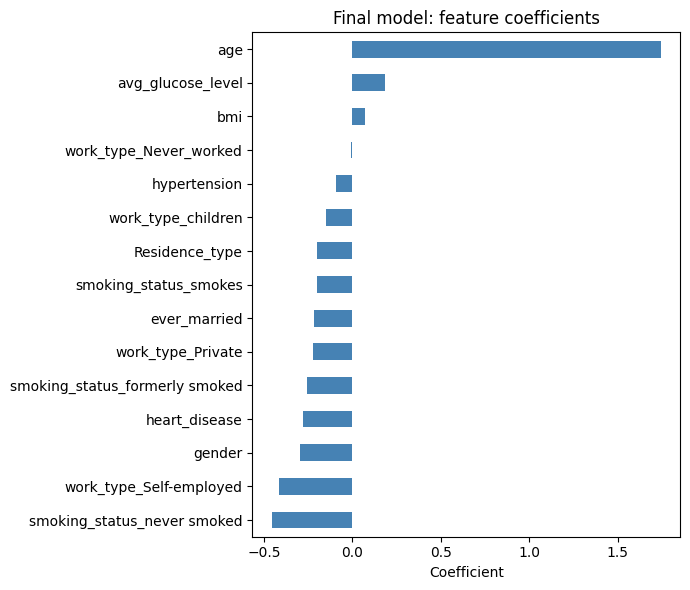

In [ ]:
plt.figure(figsize=(7, 6))
coefs.plot(kind='barh', color='steelblue')
plt.title('Final model: feature coefficients')
plt.xlabel('Coefficient')
plt.tight_layout()
plt.savefig('reports/fig6_coefficients.png', dpi=120)
plt.show()

In [ ]:
print(coefs.sort_values(ascending=False).round(2))

age                               1.74
avg_glucose_level                 0.19
bmi                               0.07
work_type_Never_worked           -0.01
hypertension                     -0.09
work_type_children               -0.15
Residence_type                   -0.20
smoking_status_smokes            -0.20
ever_married                     -0.22
work_type_Private                -0.23
smoking_status_formerly smoked   -0.26
heart_disease                    -0.28
gender                           -0.29
work_type_Self-employed          -0.42
smoking_status_never smoked      -0.46
dtype: float64


What the results show:

Age is by far the strongest predictor (1.74), much bigger than anything else.
Average glucose level (0.19) and BMI (0.07) have small positive effects.
Hypertension (-0.09) and heart disease (-0.28) came out slightly negative, which is the opposite of what you’d expect medically.
The other columns (work type, smoking, gender, marital status, residence) all sit between about -0.46 and 0, so they have small effects.

Age is by far the strongest predictor of stroke in the final model, followed by glucose level and BMI. Hypertension and heart disease had small negative coefficients, probably because they are linked to age, which already explains most of the risk. This supports my hypothesis that older patients are more likely to have a stroke, and only partly supports the hypothesis about hypertension and heart disease.

H2 (older patients are more likely to have a stroke): supported. Age dominates the model.
H1 (age, hypertension, heart disease and glucose are the strongest predictors): partly supported. Age and glucose are positive, but hypertension and heart disease are not.
Why the negative values? Age is strongly linked to hypertension and heart disease, so the model gives most of the credit to age and the others add little extra. Also, the SMOTE data and strong regularisation (C = 0.01) shrink the small effects. A negative coefficient here does not mean heart disease protects against stroke. Say this in your report.
Negative values for smoking_status_never smoked and work_type_Self-employed are relative to the dropped baseline categories (Unknown smoking and Govt_job), so don’t over-read them.